# Hiếu — Đánh giá K-Means, GMM và DBSCAN từ A đến D

Ngày thực hiện: **21/11/2026**.

Đọc nguyên file clean của An trong `data/`, không đọc raw và không cleaning lại.
Từ cùng bảng khách hàng, chạy 16 cấu hình A01–D04 cho cả 3 mô hình.
Sau đó xem chỉ số, thử seed, thử eps và mô tả cụm bằng RFM gốc.

Mở notebook tại thư mục này rồi **Restart Kernel → Run All**. Chạy đầy đủ cần vài phút.
Kết quả Excel nằm trong `data/`, hình nằm trong `figures/`.
Đây là kết quả tính lại trên clean An, không ghép chỉ số từ các notebook lịch sử.

## 1. Import và thông số chung

In [1]:
from pathlib import Path
from itertools import combinations
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import PowerTransformer, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from threadpoolctl import threadpool_limits

SEED = 42
SEEDS = [1, 7, 13, 21, 42, 99]
K_GRID = range(2, 11)
COV_GRID = ['full', 'tied', 'diag', 'spherical']
MS_GRID = [4, 6, 8, 10, 15, 20]
EPS_FACTORS = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 10.0]
OUT = Path('data')
FIG = Path('figures')
FIG.mkdir(exist_ok=True)
threadpool_limits(limits=1)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)

## 2. Đọc clean của An và tạo các đặc trưng khách hàng

In [2]:
df = pd.read_csv('data/online_retail_clean_zscore.csv',
                 dtype={'CustomerID': 'string', 'InvoiceNo': 'string'})
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Amount'] = df['Quantity'] * df['UnitPrice']
reference_date = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

customers = df.groupby('CustomerID').agg(
    FirstPurchase=('InvoiceDate', 'min'), LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'), Monetary=('Amount', 'sum'),
    QuantityTotal=('Quantity', 'sum'), Diversity=('StockCode', 'nunique'))
customers['Recency'] = (reference_date - customers['LastPurchase'].dt.normalize()).dt.days
customers['AOV'] = customers['Monetary'] / customers['Frequency']
customers['QtyPerOrder'] = customers['QuantityTotal'] / customers['Frequency']
customers['Tenure'] = (customers['LastPurchase'] - customers['FirstPurchase']).dt.total_seconds() / 86400
features = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity', 'QtyPerOrder', 'Tenure']
customers = customers.reset_index()[['CustomerID'] + features]
assert df['CustomerID'].notna().all() and customers['CustomerID'].is_unique
assert np.isfinite(customers[features].to_numpy()).all() and (customers[features] >= 0).all().all()
assert np.isclose(customers['Monetary'].sum(), df['Amount'].sum())
print('Dòng clean:', len(df), '| Khách:', len(customers), '| Ngày tham chiếu:', reference_date.date())
display(customers.head())

Dòng clean: 523577 | Khách: 4323 | Ngày tham chiếu: 2011-12-10


,CustomerID,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure
0,12347.0,3,7,4310.00,615.714286,103,351.142857,365.038194
1,12348.0,76,5,3150.16,630.032000,193,548.800000,282.752778
2,12349.0,19,1,1457.55,1457.550000,72,630.000000,0.000000
3,12350.0,311,1,334.40,334.400000,17,197.000000,0.000000
4,12352.0,37,8,3244.95,405.618750,204,120.125000,260.086111


R là số ngày lịch từ lần mua cuối đến ngày tham chiếu; F là số hóa đơn khác nhau;
M là tổng giá trị mua (GBP) trong clean. AOV = M/F; Diversity = số mã hàng khác nhau;
QtyPerOrder = tổng số lượng/F. Tenure là số ngày từ lần mua đầu đến cuối, có phần lẻ.
CustomerID không phải đầu vào số của mô hình. Giữ nguyên thứ tự khách cho mọi lượt và mọi seed.

## 3. Khai báo cấu hình A–D giống mã trong notebook của nhóm

In [3]:
RFM = ['Recency', 'Frequency', 'Monetary']
C = RFM + ['AOV', 'Diversity']
config_rows = [
    # Mã, đối chứng, feature, biến đổi, scaler, PCA, cap phân vị
    ['A01', '',    RFM, 'none',        'standard', 0.90, None],
    ['A02', 'A01', RFM, 'none',        'standard', None, None],
    ['A03', 'A01', RFM, 'none',        'standard', 2,    None],
    ['A04', 'A01', RFM, 'none',        'standard', 0.95, None],
    ['B01', 'A01', RFM, 'log_all',     'standard', 0.90, None],
    ['B02', 'B01', RFM, 'log_FM',      'standard', 0.90, None],
    ['B03', 'B01', RFM, 'yeo-johnson', 'standard', 0.90, None],
    ['B04', 'B01', RFM, 'log_all',     'minmax',   0.90, None],
    ['C01', 'B01', C,   'log_all',     'standard', 0.90, None],
    ['C02', 'C01', C + ['QtyPerOrder'], 'log_all','standard',0.90,None],
    ['C03', 'C01', C + ['Tenure'],      'log_all','standard',0.90,None],
    ['C04', 'C01', C + ['QtyPerOrder', 'Tenure'], 'log_all','standard',0.90,None],
    ['D01', 'C01', C, 'log_all', 'standard', 0.90, 99],
    ['D02', 'D01', C, 'log_all', 'standard', 0.90, 95],
    ['D03', 'D01', C, 'log_all', 'standard', 0.90, 99.5],
    ['D04', 'D01', C, 'log_all', 'robust',   0.90, 99],
]
configs = pd.DataFrame(config_rows, columns=['Config', 'Parent', 'Features', 'Transform', 'Scaler', 'PCA', 'Cap'])
# Dùng object để giữ PCA cố định 2 chiều là số nguyên, không nhầm với ngưỡng phương sai.
configs['PCA'] = pd.Series([row[5] for row in config_rows], dtype=object)
display(configs)

,Config,Parent,Features,Transform,Scaler,PCA,Cap
0,A01,,"[Recency, Frequency, Monetary]",none,standard,0.9,NaN
1,A02,A01,"[Recency, Frequency, Monetary]",none,standard,None,NaN
2,A03,A01,"[Recency, Frequency, Monetary]",none,standard,2,NaN
3,A04,A01,"[Recency, Frequency, Monetary]",none,standard,0.95,NaN
4,B01,A01,"[Recency, Frequency, Monetary]",log_all,standard,0.9,NaN
5,B02,B01,"[Recency, Frequency, Monetary]",log_FM,standard,0.9,NaN
6,B03,B01,"[Recency, Frequency, Monetary]",yeo-johnson,standard,0.9,NaN
7,B04,B01,"[Recency, Frequency, Monetary]",log_all,minmax,0.9,NaN
8,C01,B01,"[Recency, Frequency, Monetary, AOV, Diversity]",log_all,standard,0.9,NaN
9,C02,C01,"[Recency, Frequency, Monetary, AOV, Diversity,...",log_all,standard,0.9,NaN


- A: RFM chưa biến đổi; so sánh cách dùng PCA.
- B: thay cách biến đổi và scaler trên RFM.
- C: thêm đặc trưng hành vi.
- D: cap F, M, AOV, Diversity ở cấp khách trước log; giữ Recency và không xóa khách.

`none`: không biến đổi; `log_all`: log1p mọi feature; `log_FM`: chỉ log1p F và M.
Ở mỗi cấu hình, tiền xử lý chỉ fit **một lần**, cả ba mô hình dùng chung ma trận đó.

## 4. Tạo không gian đầu vào cho từng cấu hình

In [4]:
spaces = {}
space_rows = []
cap_rows = []
for _, cfg in configs.iterrows():
    name = cfg['Config']
    X = customers[cfg['Features']].copy()
    X_original = X.copy()
    capped_customers = 0
    if pd.notna(cfg['Cap']):
        cap_columns = ['Frequency', 'Monetary', 'AOV', 'Diversity']
        caps = X[cap_columns].quantile(float(cfg['Cap']) / 100)
        capped_customers = int(X[cap_columns].gt(caps).any(axis=1).sum())
        X[cap_columns] = X[cap_columns].clip(upper=caps, axis=1)
        for column in cap_columns:
            cap_rows.append({'Config': name, 'Feature': column, 'Cap_value': caps[column],
                             'Customers_capped': int((X_original[column] > caps[column]).sum())})
    if cfg['Transform'] == 'log_all': X = np.log1p(X)
    elif cfg['Transform'] == 'log_FM': X[['Frequency', 'Monetary']] = np.log1p(X[['Frequency', 'Monetary']])
    elif cfg['Transform'] == 'yeo-johnson':
        X = PowerTransformer(method='yeo-johnson', standardize=False).fit_transform(X)
    if cfg['Scaler'] == 'minmax': scaler = MinMaxScaler()
    elif cfg['Scaler'] == 'robust': scaler = RobustScaler(quantile_range=(25, 75))
    else: scaler = StandardScaler()
    Z = scaler.fit_transform(X)
    variance = 1.0
    if cfg['PCA'] is not None:
        pca = PCA(n_components=cfg['PCA'], svd_solver='full')
        Z = pca.fit_transform(Z)
        variance = pca.explained_variance_ratio_.sum()
    assert len(Z) == len(customers) and np.isfinite(Z).all()
    spaces[name] = Z
    space_rows.append({'Config': name, 'Features_count': len(cfg['Features']), 'Dimensions': Z.shape[1],
                       'PCA_variance': variance, 'Customers_capped': capped_customers})
space_info = pd.DataFrame(space_rows)
caps_table = pd.DataFrame(cap_rows)
display(space_info.round(4))

,Config,Features_count,Dimensions,PCA_variance,Customers_capped
0,A01,3,3,1.0000,0
1,A02,3,3,1.0000,0
2,A03,3,2,0.8844,0
3,A04,3,3,1.0000,0
4,B01,3,2,0.9418,0
5,B02,3,2,0.9401,0
6,B03,3,2,0.9363,0
7,B04,3,2,0.9688,0
8,C01,5,3,0.9432,0
9,C02,6,3,0.9244,0


## 5. Hàm tính chỉ số và chạy ba mô hình

K-Means: k=2…10, n_init=20, chọn Silhouette lớn nhất.
GMM: k=2…10 và 4 covariance, n_init=10, chọn BIC thấp nhất khi hội tụ và cụm nhỏ nhất ≥1% khách.
DBSCAN: ít nhất 2 cụm, nhiễu ≤5%, chọn Silhouette không nhiễu cao nhất.

Do các scaler và số chiều khác nhau, lưới eps được đổi thang theo P95 k-distance (6 hàng xóm)
của **từng cấu hình**, nhân với EPS_FACTORS. Đây là cùng một quy tắc khảo sát, không dùng một eps tuyệt đối cho mọi không gian.
Nếu không có DBSCAN đạt điều kiện thì để trống kết quả, không tự nới điều kiện.

In [5]:
def score(Z, labels, keep):
    part = labels[keep]
    k = len(np.unique(part))
    result = {'Customers_evaluated': int(keep.sum()), 'Clusters': k,
              'Coverage_pct': 100 * keep.mean(), 'Silhouette': np.nan, 'DBI': np.nan, 'CHI': np.nan}
    if 2 <= k < len(part):
        result.update(Silhouette=silhouette_score(Z[keep], part),
                      DBI=davies_bouldin_score(Z[keep], part),
                      CHI=calinski_harabasz_score(Z[keep], part))
    return result

def train_models(Z):
    km_rows = []
    for k in K_GRID:
        model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        km_rows.append({'k': k, 'Silhouette': silhouette_score(Z, model.labels_),
                        'Inertia': model.inertia_, 'Min_cluster': int(np.bincount(model.labels_).min())})
    km_grid = pd.DataFrame(km_rows)
    k = int(km_grid.loc[km_grid['Silhouette'].idxmax(), 'k'])
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)

    gm_rows = []
    for cov in COV_GRID:
        for k in K_GRID:
            model = GaussianMixture(n_components=k, covariance_type=cov, n_init=10,
                                    max_iter=300, random_state=SEED).fit(Z)
            sizes = np.bincount(model.predict(Z), minlength=k)
            gm_rows.append({'k': k, 'Covariance': cov, 'BIC': model.bic(Z),
                            'Converged': model.converged_, 'Min_cluster': int(sizes.min())})
    gm_grid = pd.DataFrame(gm_rows)
    valid = gm_grid[gm_grid['Converged'] & (gm_grid['Min_cluster'] >= 0.01 * len(Z))]
    gm = None
    if not valid.empty:
        best = valid.loc[valid['BIC'].idxmin()]
        gm = GaussianMixture(n_components=int(best['k']), covariance_type=best['Covariance'],
                             n_init=10, max_iter=300, random_state=SEED).fit(Z)

    distances = NearestNeighbors(n_neighbors=6).fit(Z).kneighbors(Z)[0][:, -1]
    eps_scale = float(np.quantile(distances, 0.95))
    assert eps_scale > 0
    db_rows = []
    for ms in MS_GRID:
        for eps in eps_scale * np.array(EPS_FACTORS):
            labels = DBSCAN(eps=float(eps), min_samples=ms).fit_predict(Z)
            keep = labels != -1
            k = len(np.unique(labels[keep]))
            noise = 100 * (~keep).mean()
            sil = np.nan
            if 2 <= k < keep.sum() and noise <= 5:
                sil = silhouette_score(Z[keep], labels[keep])
            db_rows.append({'eps': eps, 'min_samples': ms, 'Clusters': k,
                            'Noise_pct': noise, 'Silhouette_non_noise': sil})
    db_grid = pd.DataFrame(db_rows)
    valid = db_grid[db_grid['Silhouette_non_noise'].notna()]
    db = None
    if not valid.empty:
        best = valid.loc[valid['Silhouette_non_noise'].idxmax()]
        db = DBSCAN(eps=float(best['eps']), min_samples=int(best['min_samples'])).fit(Z)
    return {'K-Means': km, 'GMM': gm, 'DBSCAN': db}, (km_grid, gm_grid, db_grid)

## 6. Chạy đủ A01–D04 và lập bảng so sánh

In [6]:
models_by_config = {}
labels_by_config = {}
grids = {'K-Means': [], 'GMM': [], 'DBSCAN': []}
result_rows = []
for name, Z in spaces.items():
    started = time.monotonic()
    print('Đang chạy', name, '...', flush=True)
    models, tables = train_models(Z)
    models_by_config[name] = models
    labels_by_config[name] = {}
    for model_name, table in zip(grids, tables):
        grids[model_name].append(table.assign(Config=name))
    for model_name, model in models.items():
        if model is None:
            result_rows.append({'Config': name, 'Model': model_name, 'Note': 'Không có cấu hình đạt điều kiện'})
            continue
        labels = model.predict(Z) if model_name == 'GMM' else model.labels_
        labels_by_config[name][model_name] = labels
        result = score(Z, labels, labels != -1)
        sizes = pd.Series(labels[labels != -1]).value_counts()
        result.update(Config=name, Model=model_name, Dimensions=Z.shape[1],
                      Noise_pct=100 * (labels == -1).mean(),
                      Largest_cluster_pct=100 * sizes.max() / len(Z),
                      Min_cluster=int(sizes.min()), Note='')
        if model_name == 'K-Means': result['Parameters'] = f'k={model.n_clusters}; n_init=20'
        elif model_name == 'GMM':
            result['Parameters'] = f'k={model.n_components}; {model.covariance_type}; n_init=10'
            result['BIC'] = model.bic(Z)
        else: result['Parameters'] = f'eps={model.eps:.6g}; min_samples={model.min_samples}'
        result_rows.append(result)
    print(name, 'xong:', round(time.monotonic() - started, 1), 'giây', flush=True)
results = pd.DataFrame(result_rows)
columns = ['Config', 'Model', 'Parameters', 'Dimensions', 'Customers_evaluated', 'Clusters',
           'Silhouette', 'DBI', 'CHI', 'Coverage_pct', 'Noise_pct', 'Largest_cluster_pct', 'Min_cluster', 'BIC', 'Note']
results = results.reindex(columns=columns)
display(results.round(4))

Đang chạy A01 ...
A01 xong: 24.9 giây
Đang chạy A02 ...
A02 xong: 23.3 giây
Đang chạy A03 ...
A03 xong: 45.0 giây
Đang chạy A04 ...
A04 xong: 48.7 giây
Đang chạy B01 ...
B01 xong: 39.1 giây
Đang chạy B02 ...
B02 xong: 38.8 giây
Đang chạy B03 ...
B03 xong: 29.2 giây
Đang chạy B04 ...
B04 xong: 36.0 giây
Đang chạy C01 ...
C01 xong: 47.8 giây
Đang chạy C02 ...
C02 xong: 48.2 giây
Đang chạy C03 ...
C03 xong: 37.5 giây
Đang chạy C04 ...
C04 xong: 30.6 giây
Đang chạy D01 ...
D01 xong: 26.2 giây
Đang chạy D02 ...
D02 xong: 22.7 giây
Đang chạy D03 ...
D03 xong: 25.3 giây
Đang chạy D04 ...
D04 xong: 22.1 giây


,Config,Model,Parameters,Dimensions,Customers_evaluated,Clusters,Silhouette,DBI,CHI,Coverage_pct,Noise_pct,Largest_cluster_pct,Min_cluster,BIC,Note
0,A01,K-Means,k=2; n_init=20,3,4323,2,0.9021,0.6839,1944.9466,100.0000,0.0000,99.5142,21,NaN,
1,A01,GMM,k=6; full; n_init=10,3,4323,6,0.0237,2.1987,687.4372,100.0000,0.0000,31.9223,68,-9379.1820,
2,A01,DBSCAN,eps=0.369563; min_samples=6,3,4239,2,0.6977,0.2597,90.1593,98.0569,1.9431,97.9181,6,NaN,
3,A02,K-Means,k=2; n_init=20,3,4323,2,0.9021,0.6839,1944.9466,100.0000,0.0000,99.5142,21,NaN,
4,A02,GMM,k=7; diag; n_init=10,3,4323,7,0.0116,2.8453,718.3291,100.0000,0.0000,31.5059,64,-9570.0226,
5,A02,DBSCAN,eps=0.369563; min_samples=6,3,4239,2,0.6977,0.2597,90.1593,98.0569,1.9431,97.9181,6,NaN,
6,A03,K-Means,k=2; n_init=20,2,4323,2,0.8982,0.4760,2332.3360,100.0000,0.0000,99.5142,21,NaN,
7,A03,GMM,k=7; full; n_init=10,2,4323,7,0.0704,2.5804,982.5980,100.0000,0.0000,27.6660,50,8302.9875,
8,A03,DBSCAN,eps=1.05048; min_samples=4,2,4311,2,0.8393,0.2285,512.7789,99.7224,0.2776,99.4911,10,NaN,
9,A04,K-Means,k=2; n_init=20,3,4323,2,0.9021,0.6839,1944.9466,100.0000,0.0000,99.5142,21,NaN,


Không xếp hạng A–D bằng Silhouette chung: mỗi cấu hình có thể đổi feature, scaler, cap hoặc PCA.
BIC chỉ dùng chọn GMM trong cùng cấu hình, không so thứ hạng giữa các không gian khác nhau.
Trong cùng cấu hình, DBSCAN cũng bỏ nhiễu khi tính chỉ số. Bảng dưới tính lại trên **cùng tập khách không nhiễu DBSCAN**
để đối chiếu các mô hình trong từng cấu hình.

In [7]:
common_rows = []
for name, labels_dict in labels_by_config.items():
    if 'DBSCAN' not in labels_dict: continue
    keep = labels_dict['DBSCAN'] != -1
    for model_name, labels in labels_dict.items():
        row = score(spaces[name], labels, keep)
        row.update(Config=name, Model=model_name)
        common_rows.append(row)
common_results = pd.DataFrame(common_rows)
display(common_results.round(4))

,Customers_evaluated,Clusters,Coverage_pct,Silhouette,DBI,CHI,Config,Model
0,4239,1,98.0569,NaN,NaN,NaN,A01,K-Means
1,4239,6,98.0569,0.0237,2.0800,633.5338,A01,GMM
2,4239,2,98.0569,0.6977,0.2597,90.1593,A01,DBSCAN
3,4239,1,98.0569,NaN,NaN,NaN,A02,K-Means
4,4239,7,98.0569,0.0141,2.7365,797.7453,A02,GMM
5,4239,2,98.0569,0.6977,0.2597,90.1593,A02,DBSCAN
6,4311,2,99.7224,0.8393,0.2285,512.7789,A03,K-Means
7,4311,7,99.7224,0.0718,2.5580,1158.5753,A03,GMM
8,4311,2,99.7224,0.8393,0.2285,512.7789,A03,DBSCAN
9,4239,1,98.0569,NaN,NaN,NaN,A04,K-Means


## 7. Thử nhiều seed cho K-Means và GMM ở tất cả cấu hình

In [8]:
seed_rows, pair_rows, stability_rows = [], [], []
for name, Z in spaces.items():
    print('Thử seed:', name, flush=True)
    for model_name in ['K-Means', 'GMM']:
        selected = models_by_config[name][model_name]
        if selected is None: continue
        labels_by_seed = {}
        converged_all = True
        for seed in SEEDS:
            if model_name == 'K-Means':
                model = KMeans(n_clusters=selected.n_clusters, n_init=20, random_state=seed)
            else:
                model = GaussianMixture(n_components=selected.n_components, covariance_type=selected.covariance_type,
                                        n_init=10, max_iter=300, random_state=seed)
            labels = model.fit_predict(Z)
            labels_by_seed[seed] = labels
            converged = bool(model.converged_) if model_name == 'GMM' else True
            converged_all = converged_all and converged
            seed_rows.append({'Config': name, 'Model': model_name, 'Seed': seed,
                              'Clusters': len(np.unique(labels)), 'Converged': converged})
        values = []
        for a, b in combinations(SEEDS, 2):
            ari = adjusted_rand_score(labels_by_seed[a], labels_by_seed[b])
            values.append(ari)
            pair_rows.append({'Config': name, 'Model': model_name, 'Seed_1': a, 'Seed_2': b, 'ARI': ari})
        stability_rows.append({'Config': name, 'Model': model_name, 'ARI_mean': np.mean(values),
                               'ARI_min': min(values), 'Pairs': len(values), 'All_converged': converged_all})
stability = pd.DataFrame(stability_rows)
seed_results = pd.DataFrame(seed_rows)
pairs = pd.DataFrame(pair_rows)
display(stability.round(4))

Thử seed: A01
Thử seed: A02
Thử seed: A03
Thử seed: A04
Thử seed: B01
Thử seed: B02
Thử seed: B03
Thử seed: B04
Thử seed: C01
Thử seed: C02
Thử seed: C03
Thử seed: C04
Thử seed: D01
Thử seed: D02
Thử seed: D03
Thử seed: D04


,Config,Model,ARI_mean,ARI_min,Pairs,All_converged
0,A01,K-Means,1.0000,1.0000,15,True
1,A01,GMM,0.8403,0.7253,15,True
2,A02,K-Means,1.0000,1.0000,15,True
3,A02,GMM,0.8055,0.6855,15,True
4,A03,K-Means,1.0000,1.0000,15,True
5,A03,GMM,0.9979,0.9954,15,True
6,A04,K-Means,1.0000,1.0000,15,True
7,A04,GMM,0.8403,0.7253,15,True
8,B01,K-Means,0.9989,0.9972,15,True
9,B01,GMM,0.9915,0.9751,15,True


Giữ nguyên Z, k và tham số đã chọn; chỉ thay seed. ARI tính giữa mọi cặp trong 6 seed (15 cặp/mô hình/cấu hình).
ARI gần 1 nghĩa là ít đổi cách chia do khởi tạo, không chứng minh cụm có ý nghĩa kinh doanh.
Đây chưa phải kiểm tra lấy mẫu lại khách hoặc đánh giá khách tương lai.

## 8. Thử eps và xem tỷ lệ nhiễu của DBSCAN

In [9]:
sensitivity_rows = []
for name, models in models_by_config.items():
    selected = models['DBSCAN']
    if selected is None: continue
    Z = spaces[name]
    for factor in [0.90, 0.95, 1.0, 1.05, 1.10]:
        eps = float(selected.eps * factor)
        labels = DBSCAN(eps=eps, min_samples=selected.min_samples).fit_predict(Z)
        sizes = pd.Series(labels[labels != -1]).value_counts()
        sensitivity_rows.append({'Config': name, 'eps_factor': factor, 'eps': eps,
            'min_samples': selected.min_samples, 'Clusters': len(sizes),
            'Noise_pct': 100 * (labels == -1).mean(),
            'Largest_cluster_pct': 100 * sizes.max() / len(Z) if len(sizes) else 0,
            'ARI_vs_selected': adjusted_rand_score(selected.labels_, labels),
            'Noise_status_changed': int(((labels == -1) != (selected.labels_ == -1)).sum())})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))

,Config,eps_factor,eps,min_samples,Clusters,Noise_pct,Largest_cluster_pct,ARI_vs_selected,Noise_status_changed
0,A01,0.90,0.3326,6,1,2.3595,97.6405,0.9328,18
1,A01,0.95,0.3511,6,1,2.2207,97.7793,0.9650,12
2,A01,1.00,0.3696,6,2,1.9431,97.9181,1.0000,0
3,A01,1.05,0.3880,6,2,1.8043,98.0338,0.9696,6
4,A01,1.10,0.4065,6,2,1.7580,98.0800,0.9571,8
...,...,...,...,...,...,...,...,...,...
75,D04,0.90,0.3501,4,5,1.7349,97.8718,0.7891,23
76,D04,0.95,0.3695,4,5,1.4111,98.2420,0.8865,9
77,D04,1.00,0.3890,4,3,1.2029,98.5889,1.0000,0
78,D04,1.05,0.4084,4,3,0.9022,98.8203,0.9075,13


DBSCAN không có seed khởi tạo nên thử độ nhạy eps thay cho seed.
ARI có tính nhãn -1 và có thể cao khi một cụm quá lớn; đọc cùng số cụm, nhiễu và tỷ trọng cụm lớn nhất.

## 9. So với cấu hình cha và B01 bằng ARI

In [10]:
ablation_rows = []
for _, cfg in configs.iterrows():
    name, parent = cfg['Config'], cfg['Parent']
    for model_name, labels in labels_by_config[name].items():
        row = {'Config': name, 'Model': model_name, 'Parent': parent,
               'ARI_vs_parent': np.nan, 'ARI_vs_B01': np.nan}
        if parent and model_name in labels_by_config[parent]:
            row['ARI_vs_parent'] = adjusted_rand_score(labels, labels_by_config[parent][model_name])
        if model_name in labels_by_config['B01']:
            row['ARI_vs_B01'] = adjusted_rand_score(labels, labels_by_config['B01'][model_name])
        ablation_rows.append(row)
ablation = pd.DataFrame(ablation_rows)
display(ablation.round(4))

,Config,Model,Parent,ARI_vs_parent,ARI_vs_B01
0,A01,K-Means,,NaN,0.0058
1,A01,GMM,,NaN,0.2640
2,A01,DBSCAN,,NaN,0.2079
3,A02,K-Means,A01,1.0000,0.0058
4,A02,GMM,A01,0.6546,0.2425
5,A02,DBSCAN,A01,1.0000,0.2079
6,A03,K-Means,A01,1.0000,0.0058
7,A03,GMM,A01,0.5122,0.2537
8,A03,DBSCAN,A01,0.3816,0.6447
9,A04,K-Means,A01,1.0000,0.0058


ARI so các cách chia cùng CustomerID, không bị ảnh hưởng khi mã cụm bị hoán vị.
ARI cao là chia gần giống nhau, không phải điểm chất lượng. Ở đây mỗi cấu hình được chọn lại tham số,
nên ARI phản ánh tác động của cả cấu hình lẫn tham số được chọn, chưa tách riêng từng nguyên nhân.

## 10. Hồ sơ cụm trên RFM gốc, trước cap và biến đổi

In [11]:
profile_tables = []
assignments = customers.copy()
for name, labels_dict in labels_by_config.items():
    for model_name, labels in labels_dict.items():
        assignments[f'{name}_{model_name}'] = labels
        profile = customers[RFM].assign(Cluster=labels).groupby('Cluster').agg(
            Customers=('Monetary', 'size'), Median_R=('Recency', 'median'),
            Median_F=('Frequency', 'median'), Median_M=('Monetary', 'median'),
            Total_M=('Monetary', 'sum')).reset_index()
        profile.insert(0, 'Model', model_name)
        profile.insert(0, 'Config', name)
        profile['Customer_pct'] = 100 * profile['Customers'] / len(customers)
        profile['Monetary_pct'] = 100 * profile['Total_M'] / customers['Monetary'].sum()
        assert profile['Customers'].sum() == len(customers)
        assert np.isclose(profile['Monetary_pct'].sum(), 100)
        profile_tables.append(profile)
profiles = pd.concat(profile_tables, ignore_index=True)
display(profiles[profiles['Config'].isin(['B01', 'B03', 'C01', 'D01'])].round(2))

,Config,Model,Cluster,Customers,Median_R,Median_F,Median_M,Total_M,Customer_pct,Monetary_pct
46,B01,K-Means,0,1667,17.0,6.0,2424.04,8154568.90,38.56,85.41
47,B01,K-Means,1,2656,96.0,1.0,363.59,1392491.74,61.44,14.59
48,B01,GMM,0,1470,53.0,4.0,1548.99,3304235.39,34.00,34.61
49,B01,GMM,1,871,255.0,1.0,268.58,283787.68,20.15,2.97
50,B01,GMM,2,1116,51.0,1.0,317.88,399123.54,25.82,4.18
51,B01,GMM,3,866,6.0,7.0,2378.53,5559914.03,20.03,58.24
52,B01,DBSCAN,-1,6,20.0,48.0,86118.47,459479.06,0.14,4.81
53,B01,DBSCAN,0,4311,51.0,2.0,695.07,8360953.08,99.72,87.58
54,B01,DBSCAN,1,6,1.5,101.5,65615.83,726628.50,0.14,7.61
68,B03,K-Means,0,1959,20.0,5.0,2045.53,8490626.71,45.32,88.93


Tỷ trọng Monetary dùng tổng M gốc của cụm chia tổng M gốc tất cả khách, kể cả nhiễu.
Các nhánh D cũng được mô tả bằng RFM **trước cap**. Nhãn cụm chỉ là mã, -1 là nhiễu; không tự đặt tên VIP theo mã cụm.

## 11. Vẽ hình cho cả A–D

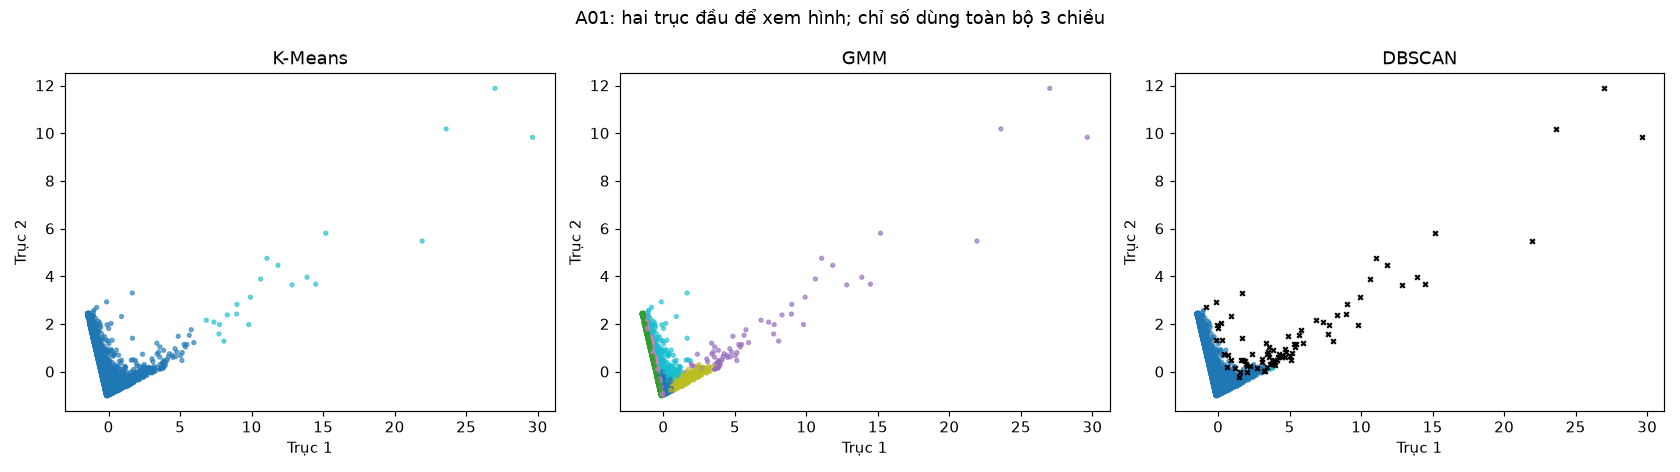

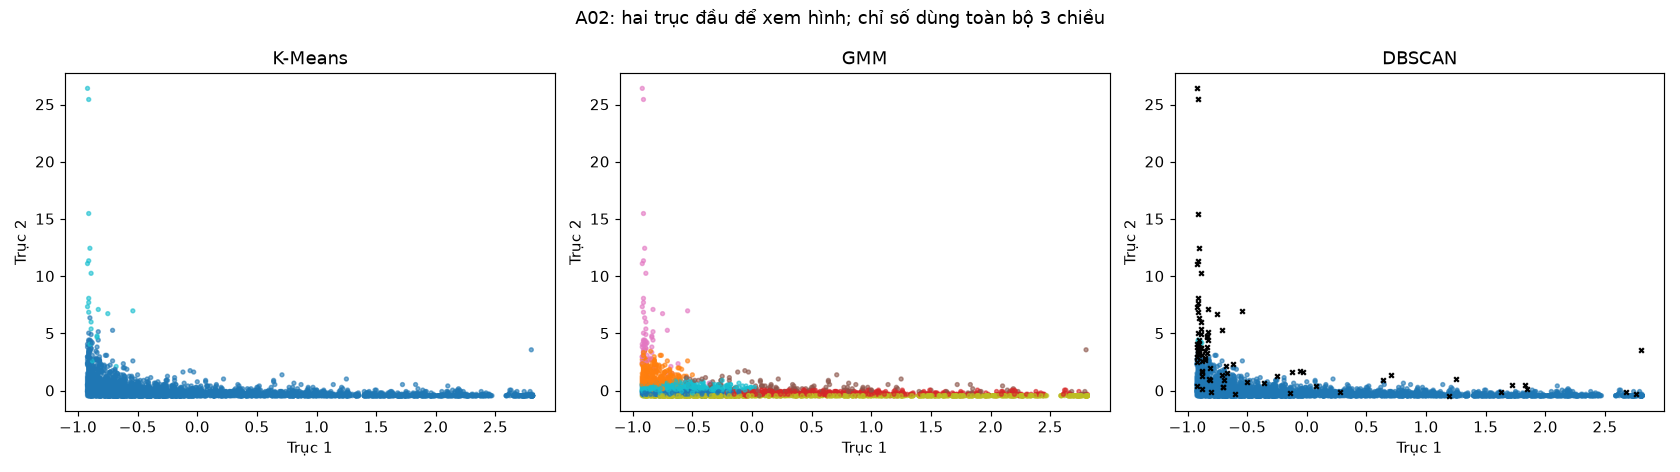

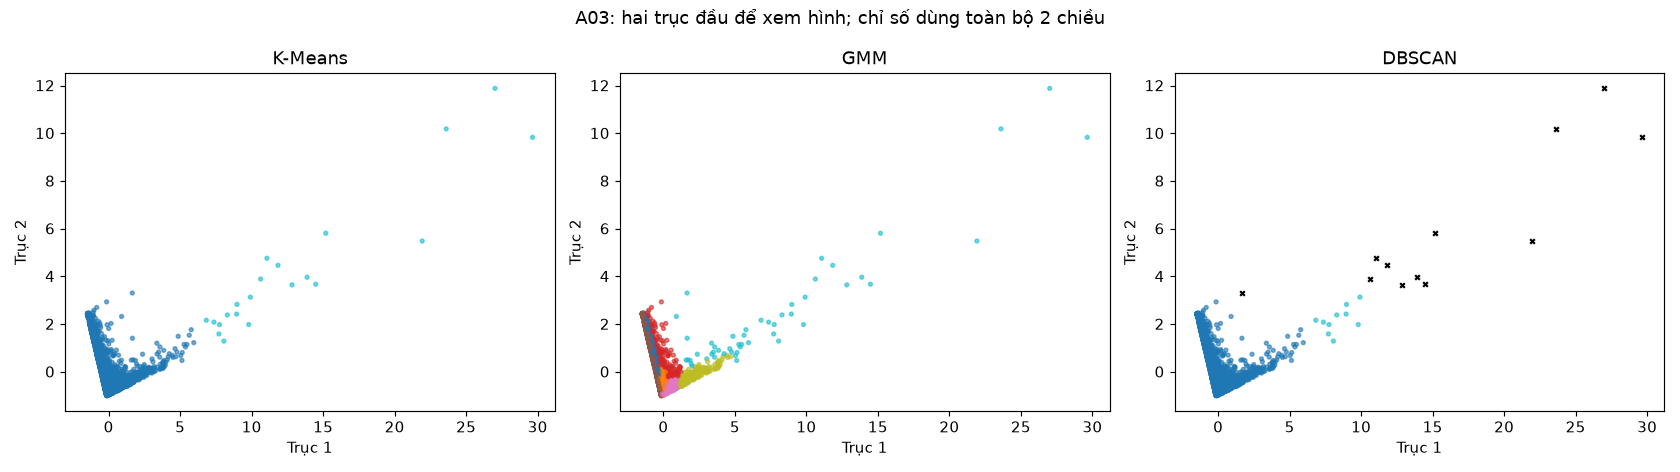

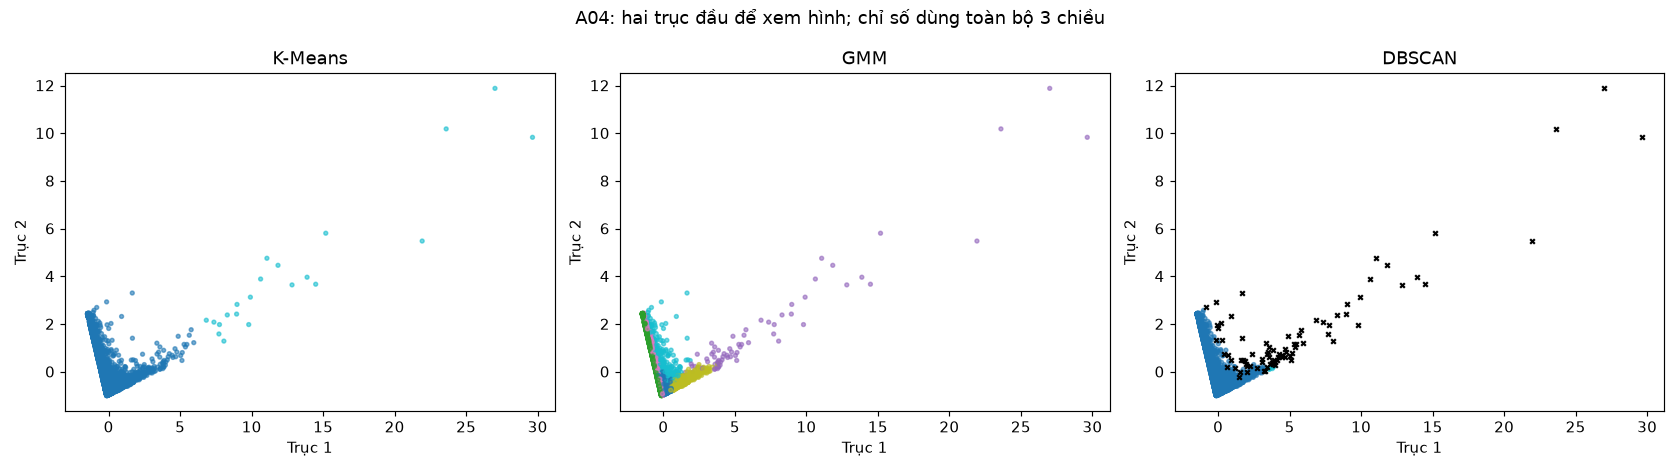

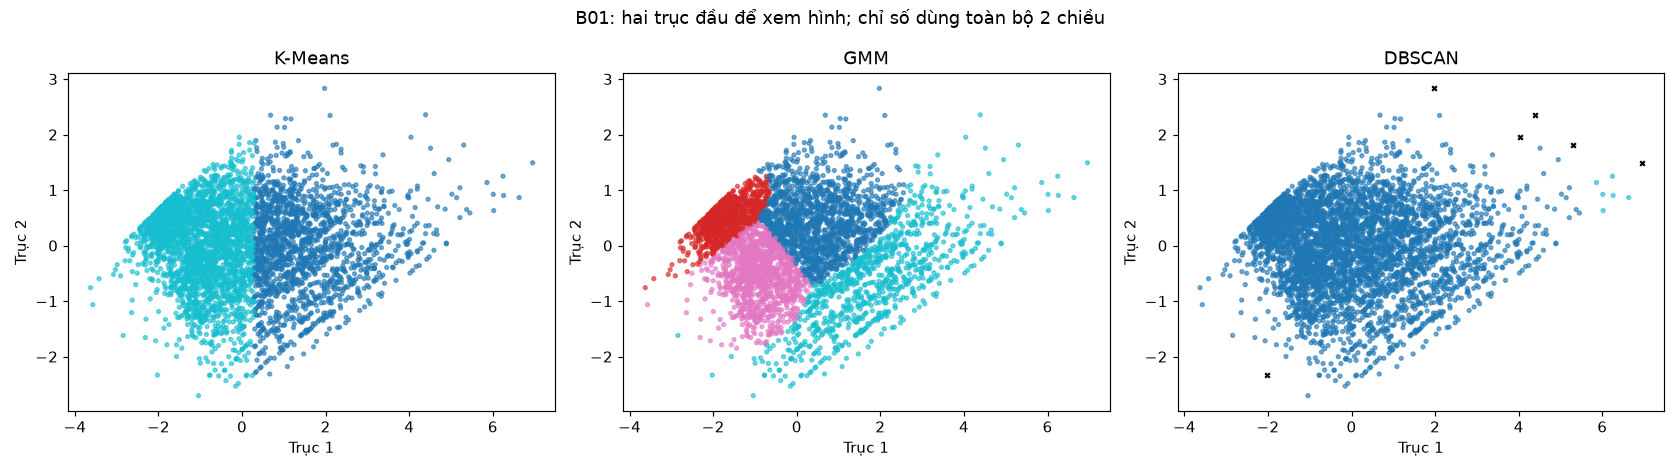

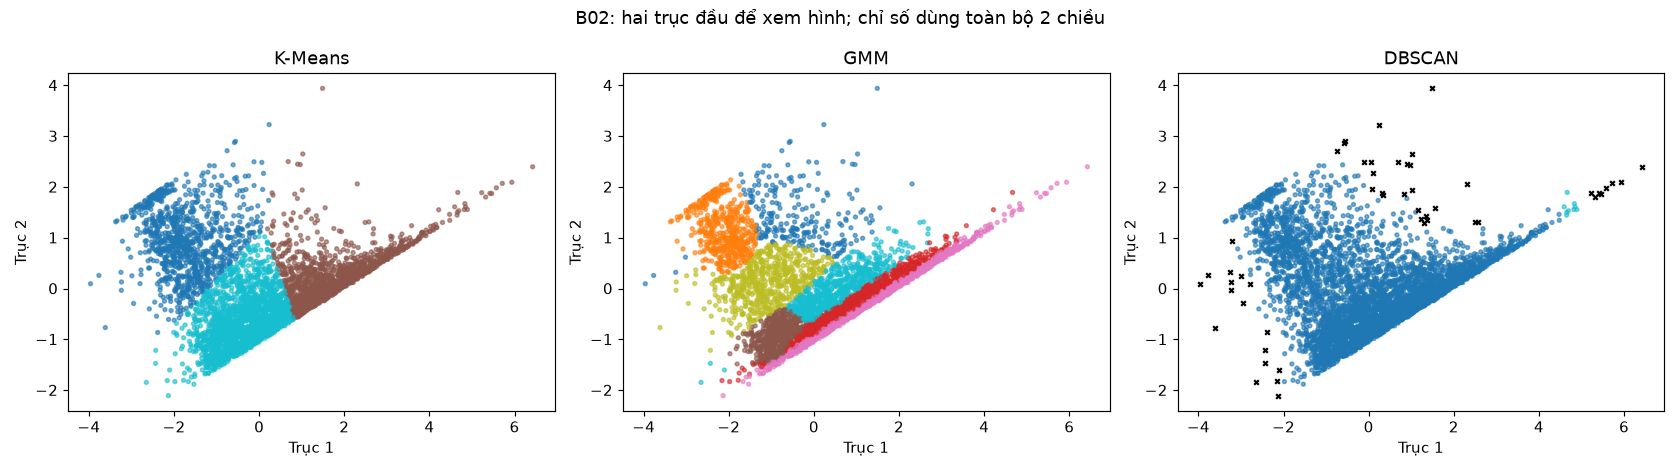

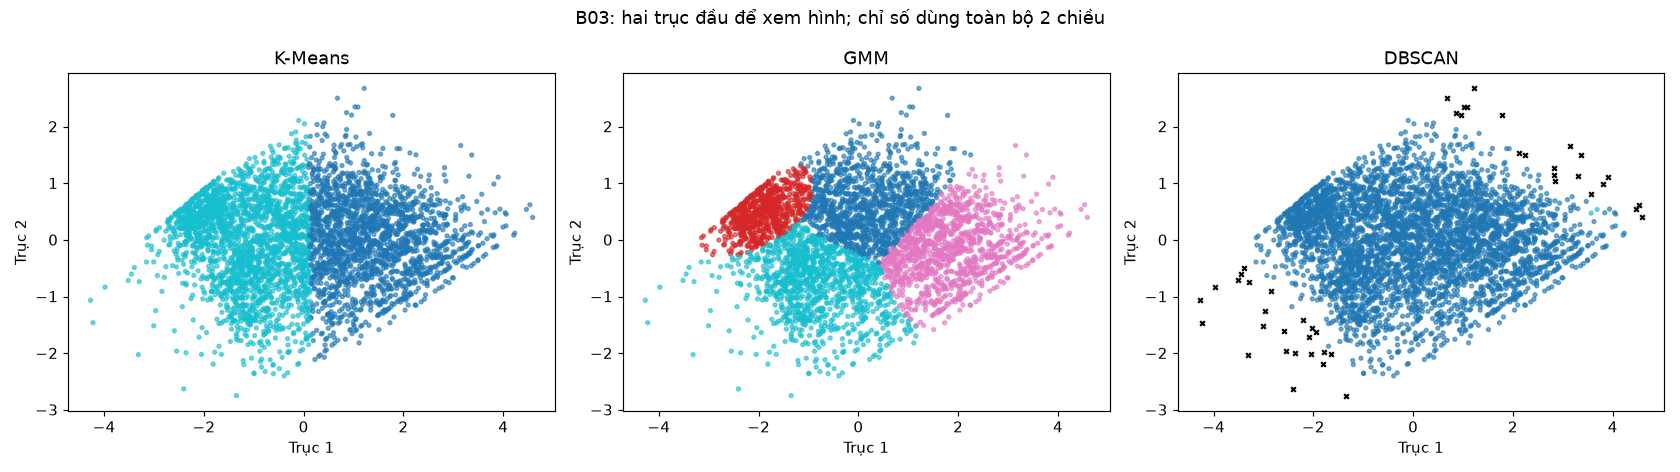

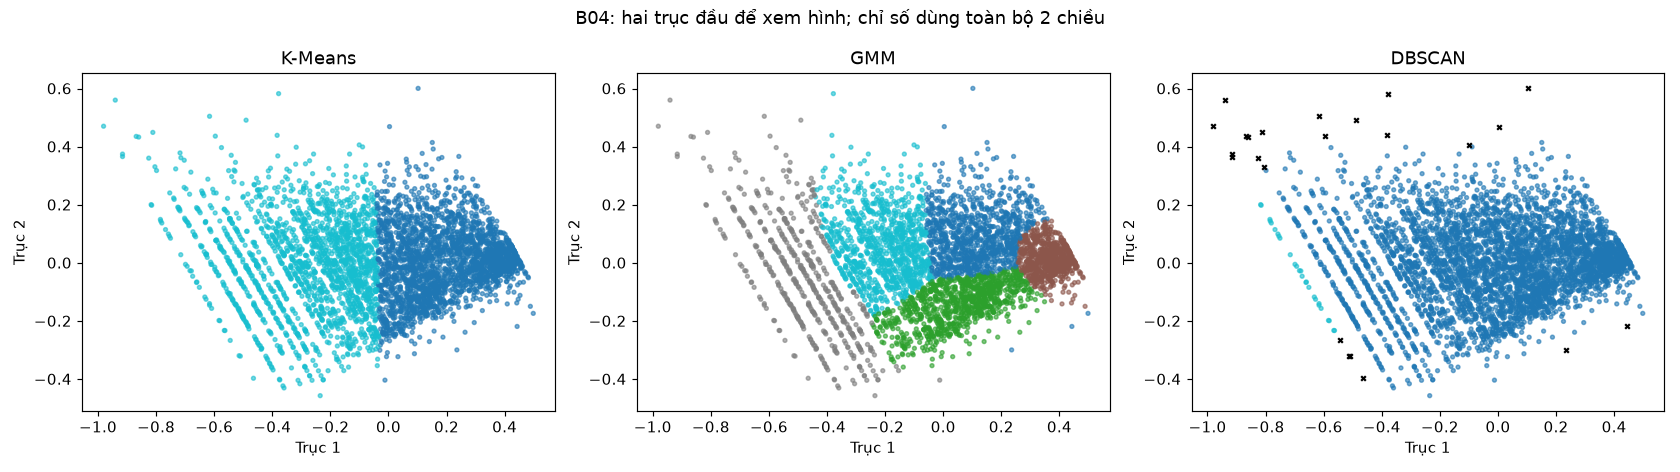

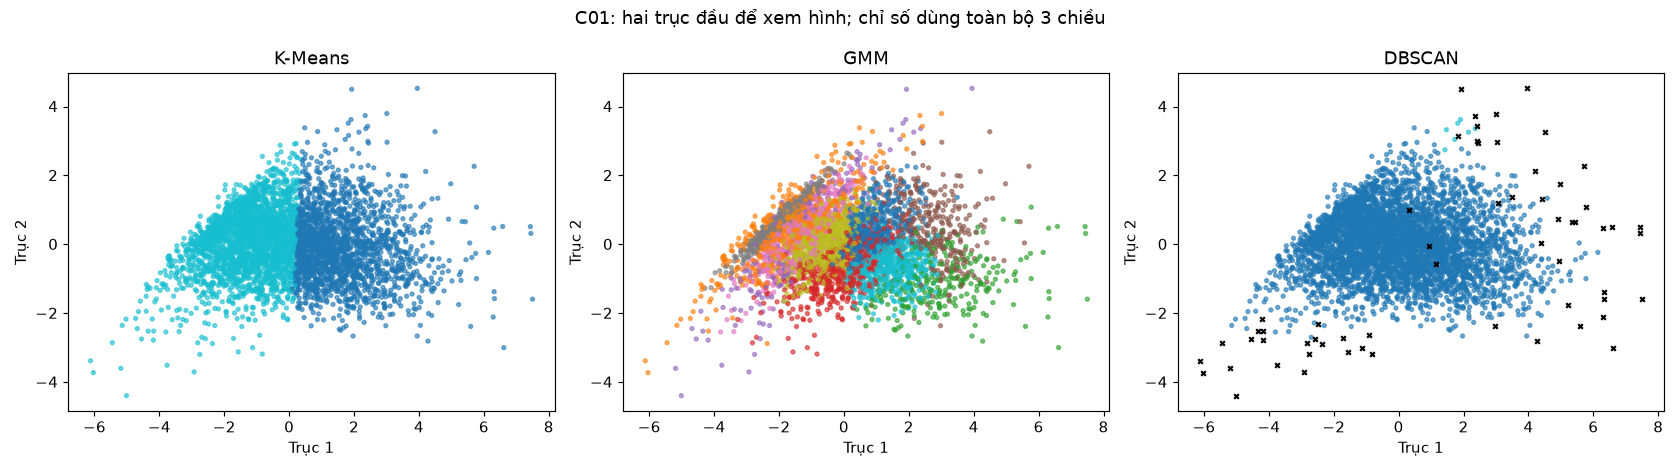

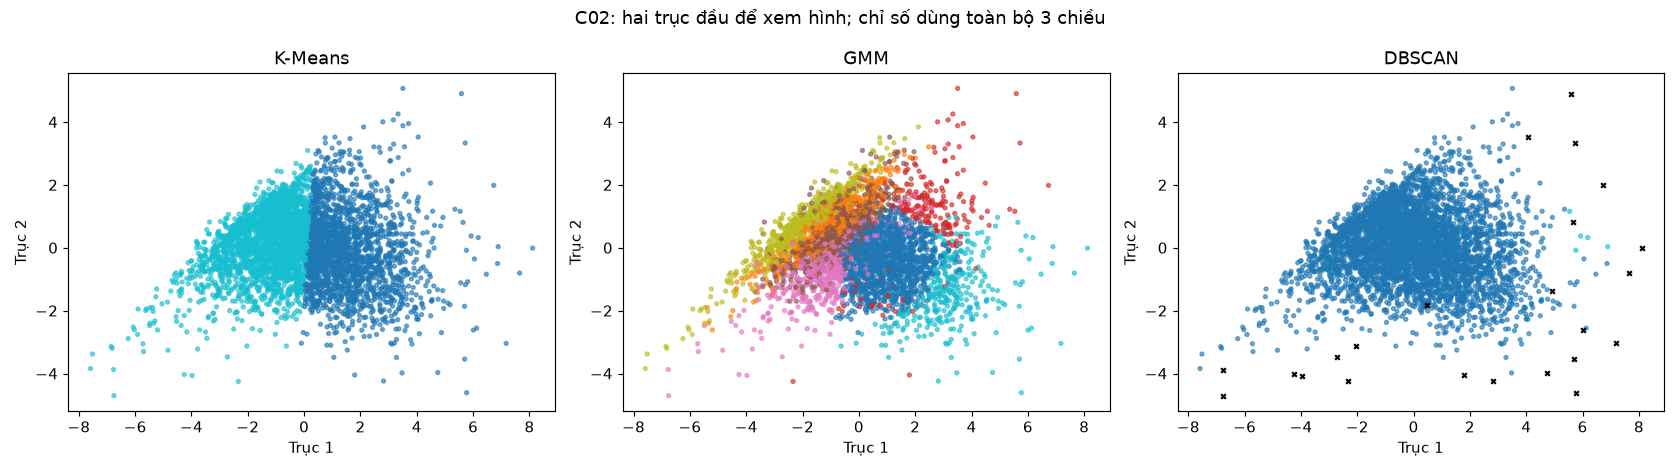

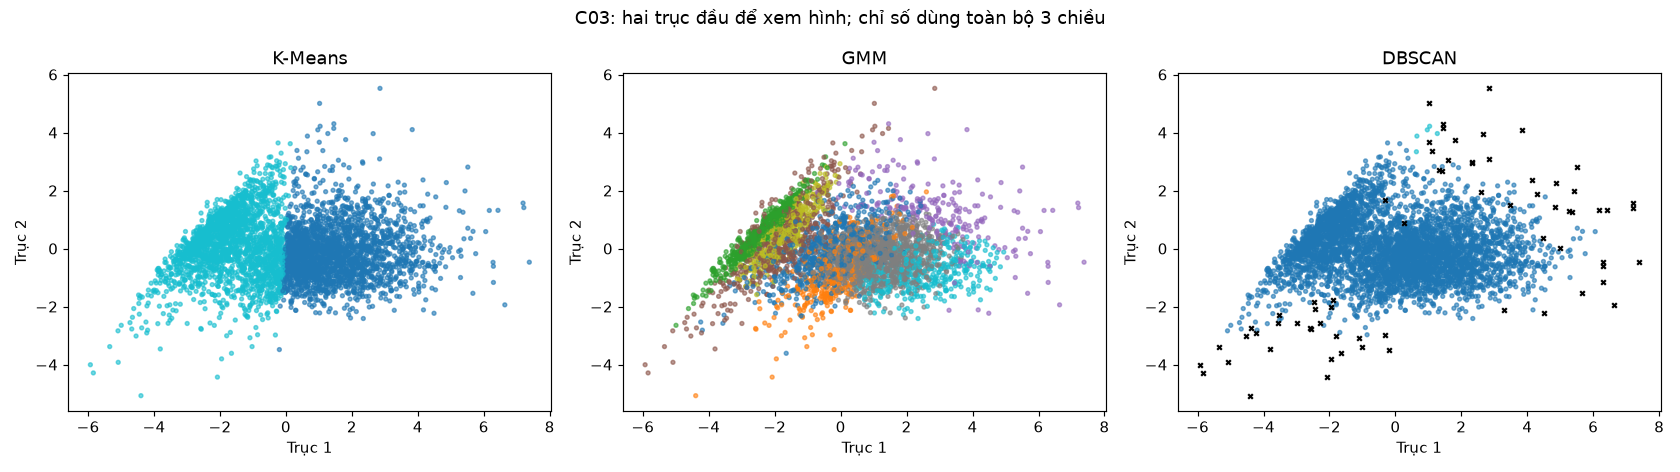

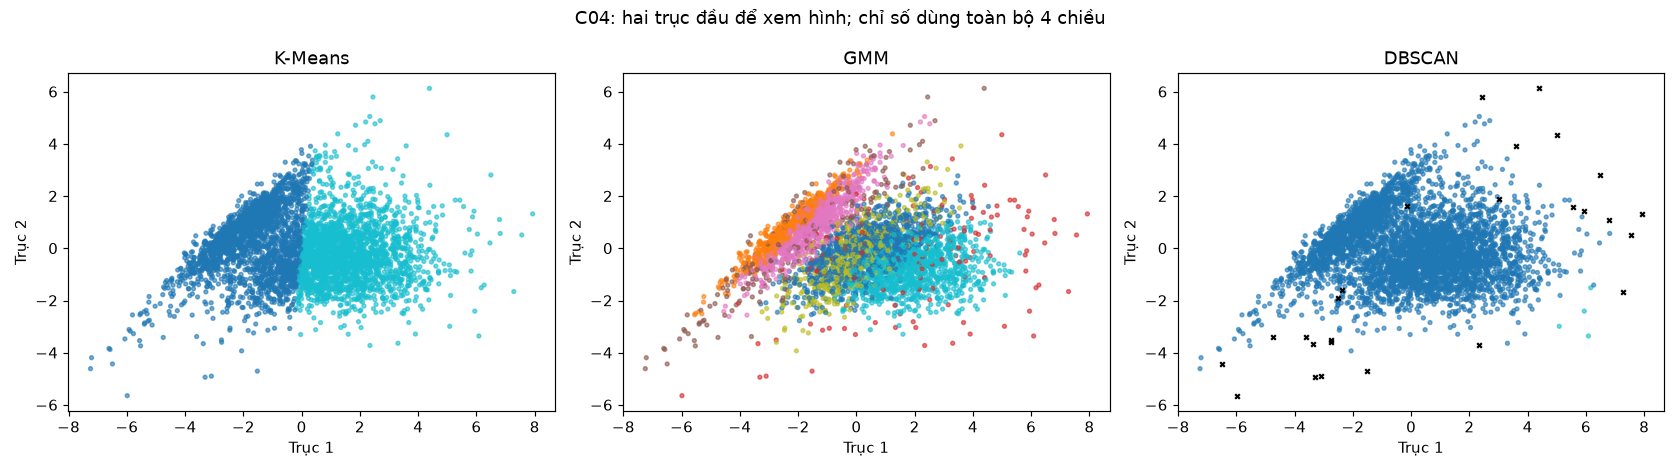

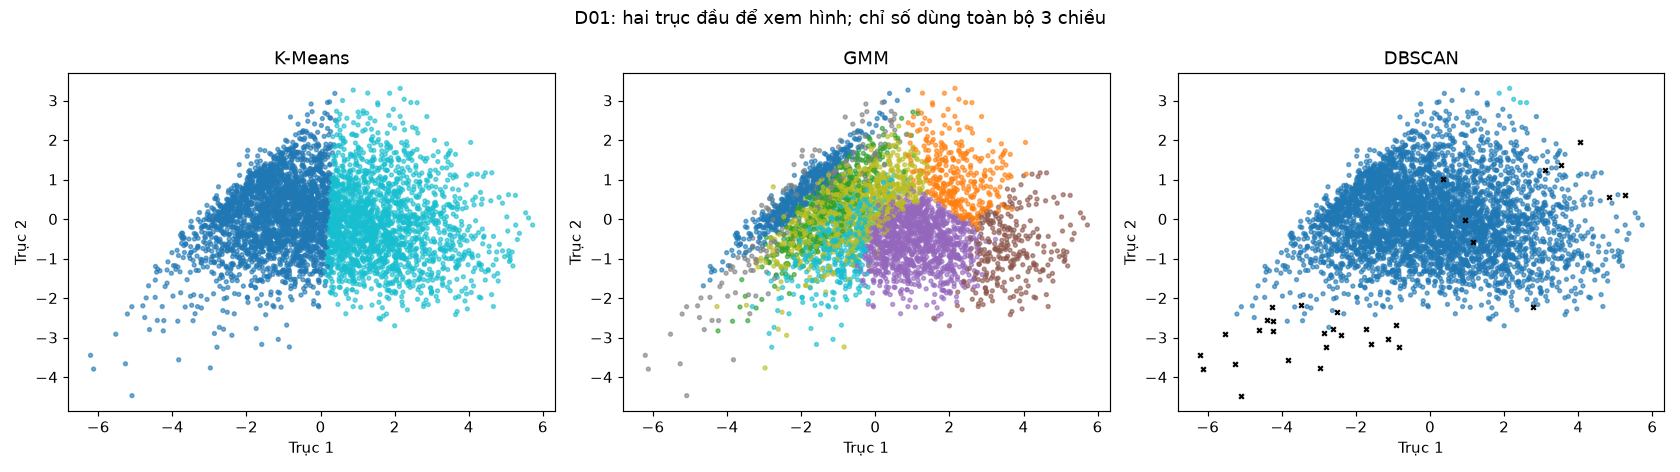

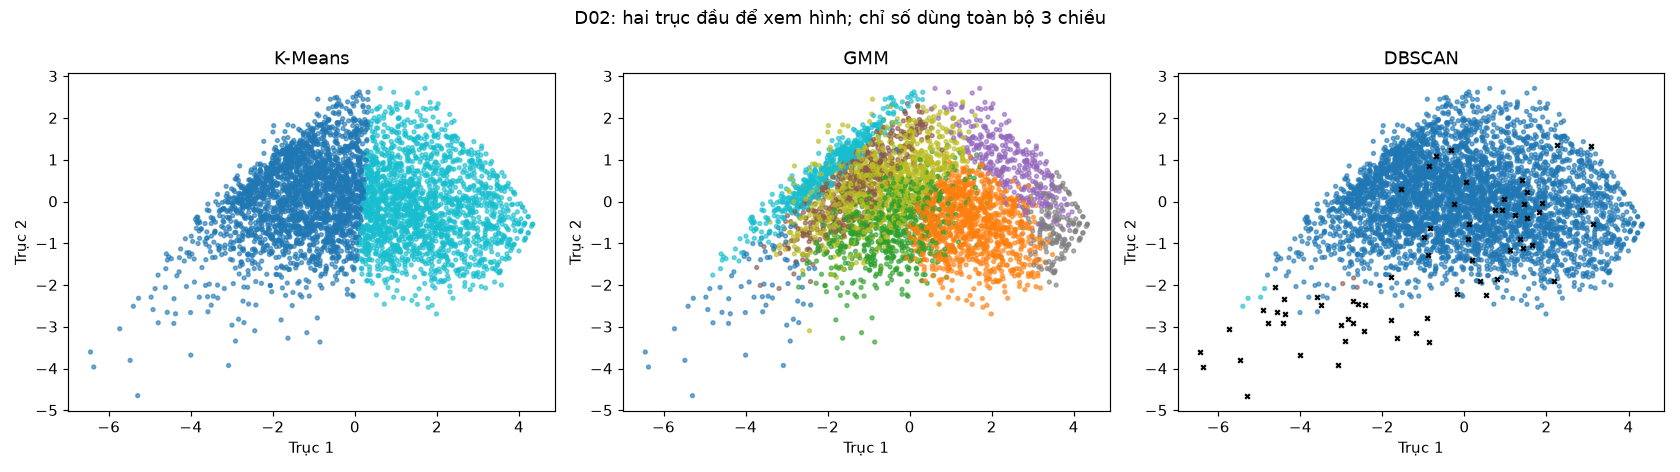

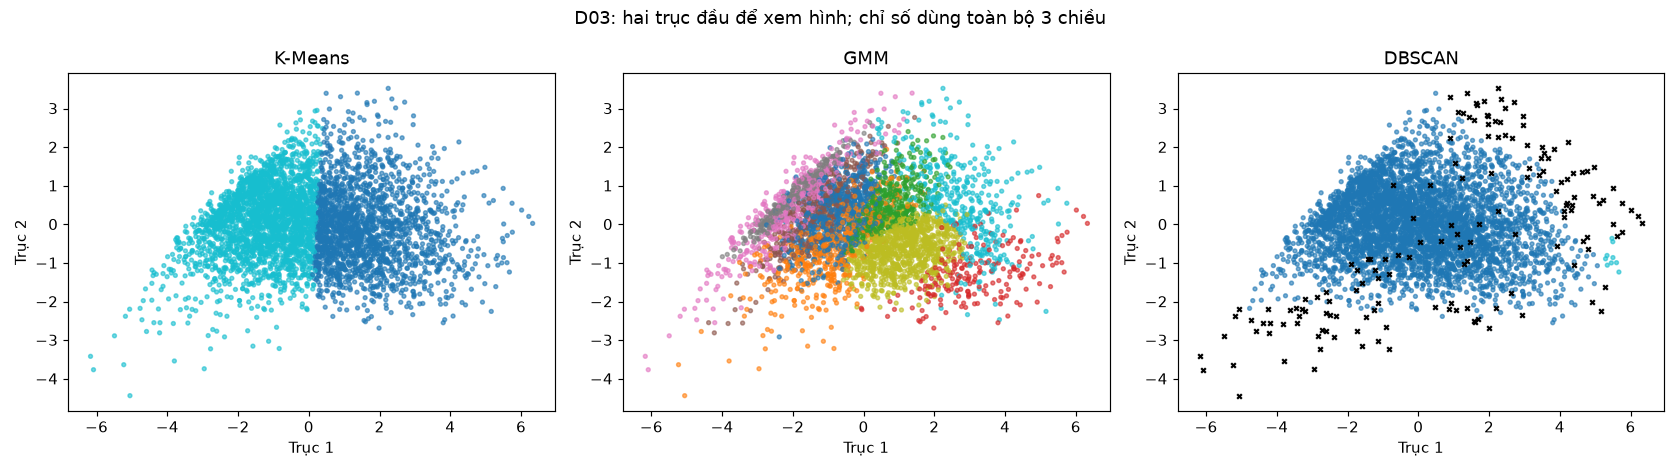

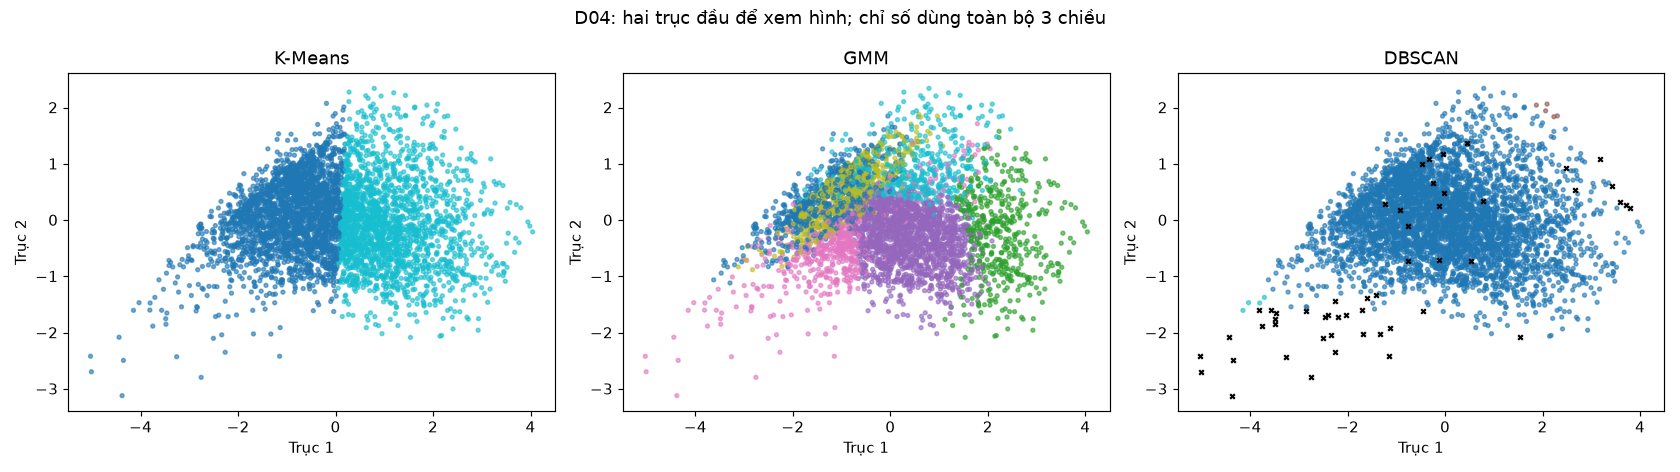

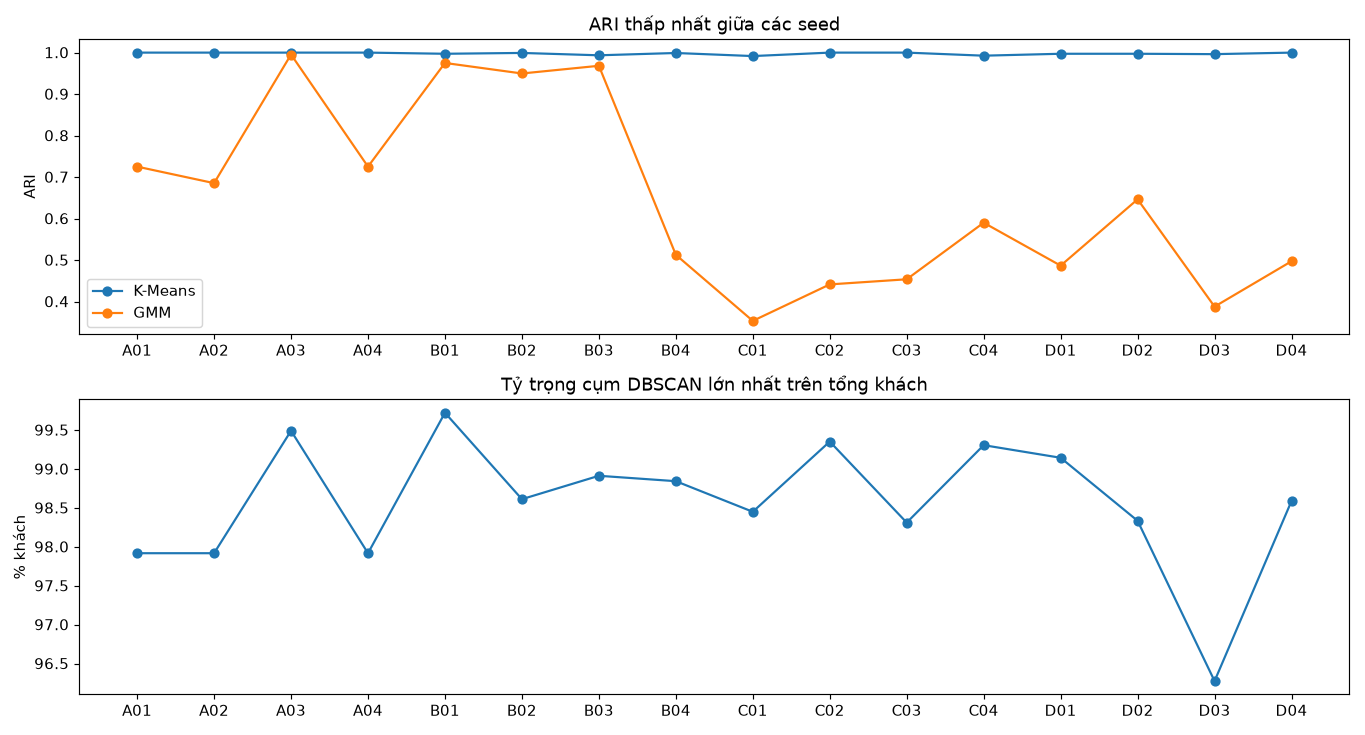

In [12]:
figure_paths = {}
for name, Z in spaces.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, model_name in zip(axes, ['K-Means', 'GMM', 'DBSCAN']):
        labels = labels_by_config[name].get(model_name)
        if labels is None:
            ax.text(0.5, 0.5, 'Không có cấu hình đạt điều kiện', ha='center', transform=ax.transAxes)
        else:
            keep = labels != -1
            y = Z[:, 1] if Z.shape[1] > 1 else np.zeros(len(Z))
            ax.scatter(Z[keep, 0], y[keep], c=labels[keep], cmap='tab10', s=7, alpha=0.6)
            if (~keep).any(): ax.scatter(Z[~keep, 0], y[~keep], c='black', marker='x', s=10, label='Nhiễu')
        ax.set_title(model_name); ax.set_xlabel('Trục 1'); ax.set_ylabel('Trục 2')
    fig.suptitle(f'{name}: hai trục đầu để xem hình; chỉ số dùng toàn bộ {Z.shape[1]} chiều')
    fig.tight_layout()
    path = FIG / f'{name}_3_mo_hinh.png'
    fig.savefig(path, dpi=130)
    figure_paths[name] = path
    plt.show()

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for model_name in ['K-Means', 'GMM']:
    part = stability[stability['Model'] == model_name]
    axes[0].plot(part['Config'], part['ARI_min'], 'o-', label=model_name)
axes[0].set_title('ARI thấp nhất giữa các seed'); axes[0].set_ylabel('ARI'); axes[0].legend()
db_part = results[results['Model'] == 'DBSCAN']
axes[1].plot(db_part['Config'], db_part['Largest_cluster_pct'], 'o-')
axes[1].set_title('Tỷ trọng cụm DBSCAN lớn nhất trên tổng khách'); axes[1].set_ylabel('% khách')
fig.tight_layout(); fig.savefig(FIG / 'tong_quan_A_D.png', dpi=140)
plt.show()